Index(['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER',
       'DAILY_YIELD', 'TOTAL_YIELD'],
      dtype='object')
Index(['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE',
       'MODULE_TEMPERATURE', 'IRRADIATION'],
      dtype='object')
R2 Score: 0.9865419035105585
MAE: 16.01985488670868


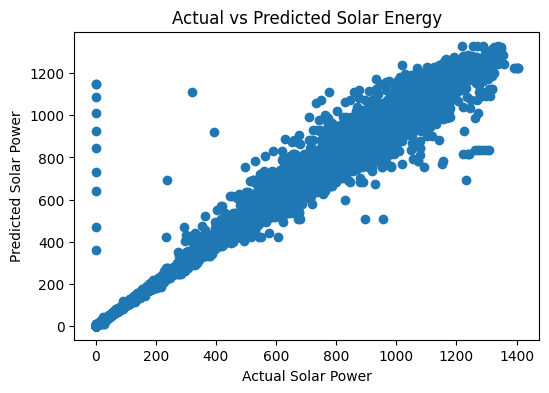

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Load both files
gen = pd.read_csv("Plant_1_Generation_Data.csv")
weather = pd.read_csv("Plant_1_Weather_Sensor_Data.csv")

print(gen.columns)
print(weather.columns)

# Convert datetime
gen['DATE_TIME'] = pd.to_datetime(gen['DATE_TIME'])
weather['DATE_TIME'] = pd.to_datetime(weather['DATE_TIME'])

# Merge on DATE_TIME
df = pd.merge(gen, weather, on='DATE_TIME')
df = df.dropna()

# Feature engineering
df['hour'] = df['DATE_TIME'].dt.hour
df['day'] = df['DATE_TIME'].dt.day
df['month'] = df['DATE_TIME'].dt.month

# Features and target
X = df[['hour','day','month',
        'AMBIENT_TEMPERATURE',
        'MODULE_TEMPERATURE',
        'IRRADIATION']]

y = df['AC_POWER']   # this is actual solar output

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# ML model
model = RandomForestRegressor(n_estimators=200)
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

# Optimization logic
def optimize(power):
    if power > 500:
        return "Use heavy appliances"
    elif power > 200:
        return "Normal usage"
    else:
        return "Save energy / use grid"

recs = [optimize(p) for p in y_pred]

# Graph: Actual vs Predicted
plt.figure(figsize=(6,4))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Solar Power")
plt.ylabel("Predicted Solar Power")
plt.title("Actual vs Predicted Solar Energy")
plt.show()
